# 2D Quantum Harmonic Oscillator — Finite Element Method

Academic FEM notebook with the original saved outputs. See [README.md](README.md) for the physical model, reported results and installation instructions.

Launch JupyterLab from the repository root. Required mesh inputs are in `data/mesh/`; plot exports are written to `outputs/`. Execute the cells in order. The domain scan solves 180 generalized eigenvalue problems and may take several minutes.

Notebook headings and plot labels are in Polish. Matrix exports in `data/reference/` are supplied comparison data and are not loaded automatically.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pint
from scipy.linalg import eigh, solve

DATA_DIR = Path("data/mesh")
OUTPUT_DIR = Path("outputs")
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Mesh data not found. Start JupyterLab from the repository root, "
        "which contains MES.ipynb and the data/ folder."
    )
OUTPUT_DIR.mkdir(exist_ok=True)


In [2]:
si = pint.UnitRegistry()

### Dane

In [3]:
L = 100 * si.nanometer 
N = 2
m_au = 0.067
nm_to_bohr = (1 * si.nanometer).to('atomic_unit_of_length').magnitude
omega_au = (10 * si.meV).to('atomic_unit_of_energy').magnitude 

def compute_jacobian(L, N):
    a = L / (2*N); a_au = a.to('atomic_unit_of_length').magnitude
    return (a_au**2)/4.0
n_loc = 9 
# Plik z położeniami węzłów N=2, L=100 nm 
wezly_N2_L100_data = pd.DataFrame(np.genfromtxt(DATA_DIR / 'wezly_N_2_L_100.dat'), columns=["lp", "x", "y"]) # tablica odsyłająca z elementu $k$ i z wezła lokalnego $i$ do globalnego numeru wezła $nlg(k,i)$

# Tablica nlg (mapowanie lokalny->globalny) dla N=2,L=100 nm
nlg_N2_L100_tab = pd.DataFrame(np.genfromtxt(DATA_DIR / 'nlg_N_2_L_100.dat'), columns=["k", "i", "glp"])

# Plik z położeniami węzłów N=4, L=100 nm 
wezly_N4_L100_data = pd.DataFrame(np.genfromtxt(DATA_DIR / 'wezly_N_4_L_100.dat'), columns=["lp", "x", "y"]) # tablica odsyłająca z elementu $k$ i z wezła lokalnego $i$ do globalnego numeru wezła $nlg(k,i)$
# Tablica nlg (mapowanie lokalny->globalny) dla N=4,L=100 nm
nlg_N4_L100_tab = pd.DataFrame(np.genfromtxt(DATA_DIR / 'nlg_N_4_L_100.dat'), columns=["k", "i", "glp"])

# Plik z położeniami węzłów N=6, L=100 nm 
wezly_N6_L100_data = pd.DataFrame(np.genfromtxt(DATA_DIR / 'wezly_N_6_L_100.dat'), columns=["lp", "x", "y"]) # tablica odsyłająca z elementu $k$ i z wezła lokalnego $i$ do globalnego numeru wezła $nlg(k,i)$
# Tablica nlg (mapowanie lokalny->globalny) dla N=6,L=100 nm
nlg_N6_L100_tab = pd.DataFrame(np.genfromtxt(DATA_DIR / 'nlg_N_6_L_100.dat'), columns=["k", "i", "glp"])

In [4]:
def q1(xi): return 0.5*xi*(xi-1)
def q2(xi): return (1-xi)*(1+xi)
def q3(xi): return 0.5*xi*(xi+1)

w1=w2 = (18+np.sqrt(30))/36; w3=w4 = (18-np.sqrt(30))/36
p2= np.sqrt( (3/7)-(2/7) *np.sqrt((6/5))); p1=p2*(-1); p3=np.sqrt( (3/7)+(2/7) *np.sqrt((6/5))); p4=p3*(-1)
wg = np.array([w1, w2, w3, w4]); pi = np.array([p1, p2, p3, p4])

def h_vec(xi1 ,xi2): 
    q1_1, q2_1, q3_1 = q1(xi1), q2(xi1), q3(xi1)
    q1_2, q2_2, q3_2 = q1(xi2), q2(xi2), q3(xi2)
    return np.array([
        q1_1*q1_2, #h1
        q3_1*q1_2, #h2
        q1_1*q3_2, #h3
        q3_1*q3_2, #h4
        q2_1*q1_2, #h5
        q3_1*q2_2, #h6
        q1_1*q2_2, #h7
        q2_1*q3_2, #h8
        q2_1*q2_2  #h9
        ])

### Lokalna macierz przekrywania

In [ ]:
def compute_S_loc(L, N, n_loc=9,):
    jac = compute_jacobian(L, N)
    S_loc = np.zeros((n_loc, n_loc))
    for l in range(4): 
        for n in range(4): 
            h = h_vec(pi[l], pi[n])
            S_loc += np.outer(h, h) * wg[l] * wg[n] * jac   
    S_loc_df = (pd.DataFrame(S_loc).stack().reset_index().rename(columns={"level_0": "i", "level_1": "j", 0: "val"}))
    return S_loc, S_loc_df
S_loc, S_loc_df = compute_S_loc(L, N, n_loc=9,)
print(S_loc_df)

    i  j           val
0   0  0   3967.849812
1   0  1   -991.962453
2   0  2   -991.962453
3   0  3    247.990613
4   0  4   1983.924906
.. .. ..           ...
76  8  4   7935.699624
77  8  5   7935.699624
78  8  6   7935.699624
79  8  7   7935.699624
80  8  8  63485.596994

[81 rows x 3 columns]


### Macierz energii kinetycznej

In [6]:
def compute_T_loc(n_loc=9, delta=1e-6):
    T_loc = np.zeros((n_loc, n_loc))
    for l in range(4):
        for n in range(4): 
            h = h_vec(pi[l], pi[n])
            h_plux_xi1 = h_vec(pi[l] + delta, pi[n])
            h_minus_xi1 = h_vec(pi[l] - delta, pi[n])
            h_plux_xi2 = h_vec(pi[l], pi[n] + delta)
            h_minus_xi2 = h_vec(pi[l], pi[n] - delta)
            dh_dxi1 = (h_plux_xi1 - h_minus_xi1) / (2.0 * delta)
            dh_dxi2 = (h_plux_xi2 - h_minus_xi2) / (2.0 * delta)
            
            T_loc += (1/(2*m_au)) * wg[l] * wg[n] * (np.outer(dh_dxi1, dh_dxi1) + np.outer(dh_dxi2, dh_dxi2))
    T_loc_df = (pd.DataFrame(T_loc).stack().reset_index().rename(columns={"level_0": "i", "level_1": "j", 0: "val"}))
    return T_loc, T_loc_df
T_loc, T_loc_df = compute_T_loc(n_loc=9)
print(T_loc_df)

    i  j        val
0   0  0   4.643449
1   0  1  -0.248756
2   0  2  -0.248756
3   0  3  -0.165837
4   0  4  -1.492537
.. .. ..        ...
76  8  4  -7.960199
77  8  5  -7.960199
78  8  6  -7.960199
79  8  7  -7.960199
80  8  8  42.454395

[81 rows x 3 columns]


### Macierz energii potencjalnej

In [7]:
def f1(xi): return 0.5*(1-xi)
def f2(xi): return 0.5*(1+xi)

def g_vec(xi1, xi2): 
    f1_1, f2_1 = f1(xi1), f2(xi1)
    f1_2, f2_2 = f1(xi2), f2(xi2)
    return np.array([
        f1_1 * f1_2,  # g1
        f2_1 * f1_2,  # g2
        f1_1 * f2_2,  # g3
        f2_1 * f2_2   # g4
        ])
def compute_V_loc(L, N, n_loc=9, k_element=11):
    V_loc = np.zeros((n_loc, n_loc))
    jac = compute_jacobian(L, N)
    corners_idx = []
    for local_i in range(1, 5):
        row = nlg_N2_L100_tab[(nlg_N2_L100_tab['k'] == k_element) & (nlg_N2_L100_tab['i'] == local_i)]
        corners_idx.append(int(row['glp'].values[0]))
    x_nodes = np.array([])
    y_nodes = np.array([])
    for glp in corners_idx:
        node_row = wezly_N2_L100_data[wezly_N2_L100_data['lp'] == glp]
        x_nodes = np.append(x_nodes, node_row['x'].values[0] * nm_to_bohr)
        y_nodes = np.append(y_nodes, node_row['y'].values[0] * nm_to_bohr)

    for l in range(4):
        for n in range(4): 
            h = h_vec(pi[l], pi[n])
            g = g_vec(pi[l], pi[n])
            x = np.dot(x_nodes, g)
            y = np.dot(y_nodes, g)
            
            V_loc += jac * 0.5*m_au*(omega_au**2) *(x**2 + y**2)* wg[l] * wg[n] * np.outer(h, h)

    V_loc_df = (pd.DataFrame(V_loc).stack().reset_index().rename(columns={"level_0": "i", "level_1": "j", 0: "val"}))
    return V_loc, V_loc_df
V_loc, V_loc_df = compute_V_loc(L, N, n_loc=9, k_element=11)
print(f"Macierz energii potencjalnej dla elementu k={11}:")
print(V_loc_df)

Macierz energii potencjalnej dla elementu k=11:
    i  j        val
0   0  0   0.286186
1   0  1  -0.393506
2   0  2  -0.393506
3   0  3   0.178866
4   0  4  -0.214640
.. .. ..        ...
76  8  4   1.144744
77  8  5   9.157953
78  8  6   1.144744
79  8  7   9.157953
80  8  8  36.631811

[81 rows x 3 columns]


### Składamy macierze globalne

In [8]:
def compute_global_matrices(S_loc, T_loc, N, L, wezly_N_L_data, nlg_N_L_data):
    n_global = (4 * N + 1)**2  # 81 dla N=2
    S_global = np.zeros((n_global, n_global))
    T_global = np.zeros((n_global, n_global))
    V_global = np.zeros((n_global, n_global))
    jac  = compute_jacobian(L, N)
    n_elem = int(nlg_N_L_data['k'].max())  # 16 dla N=2

    for k in range(1, n_elem + 1):
        rows_k = nlg_N_L_data[nlg_N_L_data['k'] == k]
        
        local_to_global = {}
        for _, row in rows_k.iterrows():
            local_i = int(row['i'])
            global_i = int(row['glp'])
            local_to_global[local_i] = global_i
        
        V_loc_k = np.zeros((n_loc, n_loc))
        
        corners_idx = []
        for local_i in range(1, 5):
            corners_idx.append(local_to_global[local_i])
        
        x_nodes = np.array([])
        y_nodes = np.array([])
        for glp in corners_idx:
            node_row = wezly_N_L_data[wezly_N_L_data['lp'] == glp]
            x_nodes = np.append(x_nodes, node_row['x'].values[0] * nm_to_bohr)
            y_nodes = np.append(y_nodes, node_row['y'].values[0] * nm_to_bohr)
        
        for l in range(4):
            for n in range(4):
                h = h_vec(pi[l], pi[n])
                g = g_vec(pi[l], pi[n])
                x = np.dot(x_nodes, g)
                y = np.dot(y_nodes, g)
                
                V_loc_k += jac * 0.5 * m_au * (omega_au**2) * (x**2 + y**2) * wg[l] * wg[n] * np.outer(h, h)
        
        for i1_local in range(1, 10):
            I = local_to_global[i1_local] - 1
            
            for i2_local in range(1, 10):
                J = local_to_global[i2_local] - 1
                
                i1_array = i1_local - 1
                i2_array = i2_local - 1
                
                S_global[I, J] += S_loc[i1_array, i2_array]
                T_global[I, J] += T_loc[i1_array, i2_array]
                V_global[I, J] += V_loc_k[i1_array, i2_array]

    H_global = T_global + V_global


    S_glob_df = pd.DataFrame(S_global)
    H_glob_df = pd.DataFrame(H_global)

    SH_glob_df = (S_glob_df.stack().reset_index().rename(columns={"level_0": "i", "level_1": "j", 0: "S"}))
    SH_glob_df["H"] = H_glob_df.stack().values  
    return S_global, H_global, SH_glob_df
S_global, H_global, SH_glob_df = compute_global_matrices(S_loc, T_loc, N=2, L=L, 
                                                         wezly_N_L_data=wezly_N2_L100_data,nlg_N_L_data=nlg_N2_L100_tab)
print(SH_glob_df)

       i   j             S           H
0      0   0   3967.849812   32.975865
1      0   1   -991.962453   -6.151343
2      0   2      0.000000    0.000000
3      0   3      0.000000    0.000000
4      0   4   -991.962453   -6.151343
...   ..  ..           ...         ...
6556  80  76      0.000000    0.000000
6557  80  77      0.000000    0.000000
6558  80  78   7935.699624   41.263796
6559  80  79   7935.699624   41.263796
6560  80  80  63485.596994  335.508879

[6561 rows x 4 columns]


### Warunki brzegowe

In [ ]:
def boundary_conditions(S_global, H_global, wezly_data, L):
    L_nm = L.magnitude  
    L_half = L_nm / 2  
    boundary_nodes = []

    for idx, row in wezly_data.iterrows():
        x = row['x']
        y = row['y']
        lp = int(row['lp'])
        
        if abs(abs(x) - L_half) < 1e-6 or abs(abs(y) - L_half) < 1e-6:
            boundary_nodes.append(lp)

    for node in boundary_nodes:
        i = node - 1  
        S_global[i, :] = 0.0
        S_global[:, i] = 0.0
        H_global[i, :] = 0.0
        H_global[:, i] = 0.0
        
        S_global[i, i] = 1.0
        H_global[i, i] = -1410.0

    S_glob_df = pd.DataFrame(S_global)
    H_glob_df = pd.DataFrame(H_global)

    SH_glob_df = (S_glob_df.stack().reset_index()
                  .rename(columns={"level_0": "i", "level_1": "j", 0: "S"}))
    SH_glob_df["H"] = H_glob_df.stack().values  
    return S_global, H_global, SH_glob_df

S_global_, H_global, SH_glob_df = boundary_conditions(S_global, H_global, wezly_data=wezly_N2_L100_data, L=L)
print(SH_glob_df)

       i   j             S            H
0      0   0      1.000000 -1410.000000
1      0   1      0.000000     0.000000
2      0   2      0.000000     0.000000
3      0   3      0.000000     0.000000
4      0   4      0.000000     0.000000
...   ..  ..           ...          ...
6556  80  76      0.000000     0.000000
6557  80  77      0.000000     0.000000
6558  80  78      0.000000     0.000000
6559  80  79      0.000000     0.000000
6560  80  80  63485.596994   335.508879

[6561 rows x 4 columns]


### 7 Widmo

In [10]:
def calculate_eigenstates(S_global, H_global):
    E_au, C = eigh(H_global, S_global) 
    E_meV = E_au * (1 * si.atomic_unit_of_energy).to('millielectron_volt').magnitude
    pos_mask = E_au > 0
    pos_indices = np.where(pos_mask)[0]
    first6 = pos_indices[:6]
    print("Indeksy 6 najniższych dodatnich stanów:", first6)
    print("Odpowiadające energie [meV]:", E_meV[first6])
    return E_au, E_meV, C, first6
E_au_n2L100, E_meV_n2L100, C_n2L100, first6_n2L100 = calculate_eigenstates(S_global, H_global)

Indeksy 6 najniższych dodatnich stanów: [32 33 34 35 36 37]
Odpowiadające energie [meV]: [10.83537018 21.43393602 21.43393602 32.03250186 34.31182114 34.31182117]


In [11]:
def eval_psi_on_elements(psi_n, nlg_tab, wezly_data, n_points_per_dir=5):
    xs = []
    ys = []
    vals = []

    n_elem = int(nlg_tab["k"].max())
    xi_grid = np.linspace(-1.0, 1.0, n_points_per_dir)

    for k in range(1, n_elem + 1):
        rows_k = nlg_tab[nlg_tab["k"] == k].sort_values("i")

        glob_ids = rows_k["glp"].astype(int).values  
        psi_local = psi_n[glob_ids - 1]

        corner_glp = [
            int(rows_k[rows_k["i"] == i]["glp"].values[0])
            for i in range(1, 5)
        ]

        x_nodes = []
        y_nodes = []
        for glp in corner_glp:
            node_row = wezly_data[wezly_data["lp"] == glp].iloc[0]
            x_nodes.append(node_row["x"])  # [nm]
            y_nodes.append(node_row["y"])  # [nm]
        x_nodes = np.array(x_nodes)
        y_nodes = np.array(y_nodes)

        for xi1 in xi_grid:
            for xi2 in xi_grid:
                h = h_vec(xi1, xi2)  
                g = g_vec(xi1, xi2)  

                x_val = np.dot(x_nodes, g)   # [nm]
                y_val = np.dot(y_nodes, g)   # [nm]
                psi_val = np.dot(psi_local, h)

                xs.append(x_val)
                ys.append(y_val)
                vals.append(psi_val)

    return np.array(xs), np.array(ys), np.array(vals)


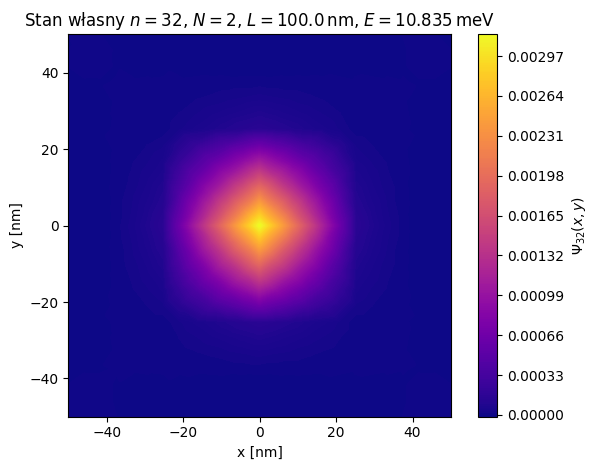

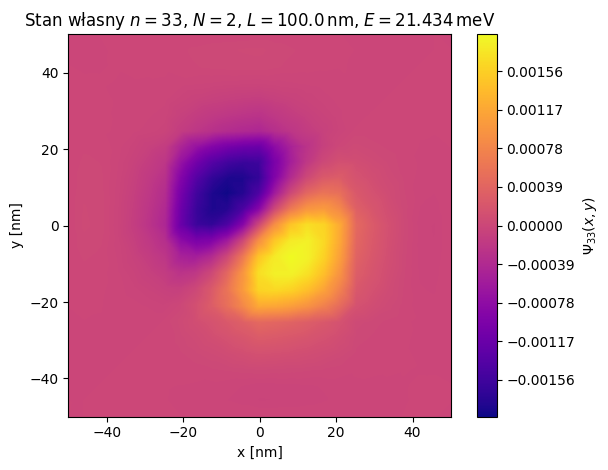

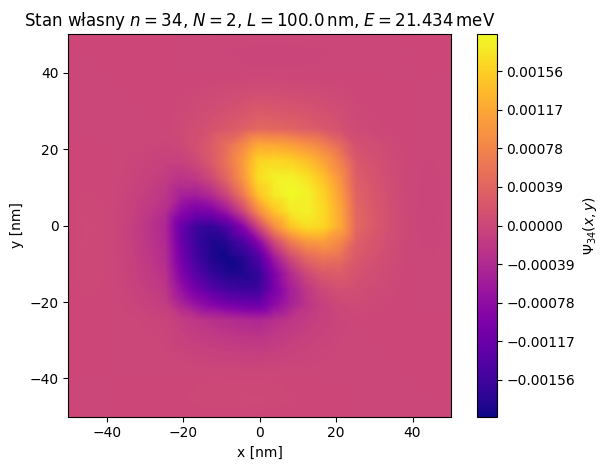

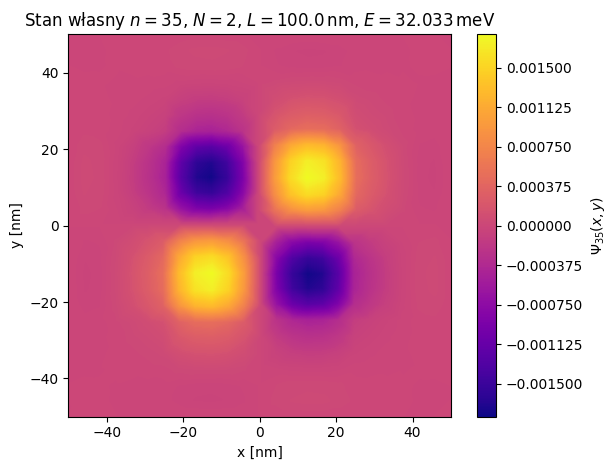

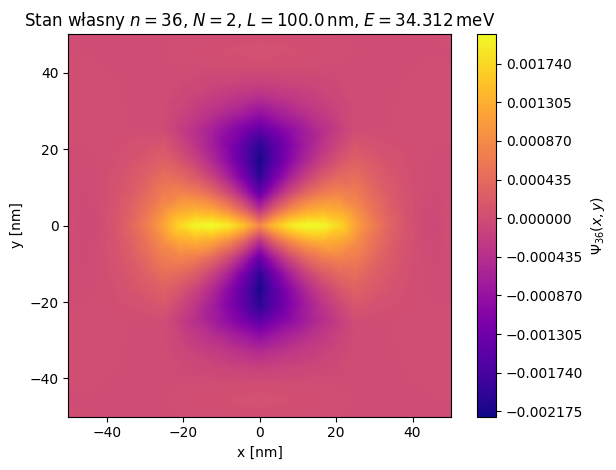

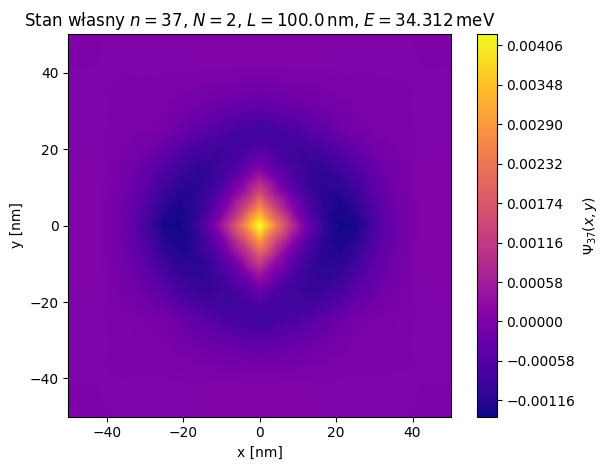

In [12]:
for idx in first6_n2L100:
    psi_n2l100 = C_n2L100[:, idx].real
    xs_n2l100, ys_n2l100, vals_n2l100 = eval_psi_on_elements(psi_n2l100, nlg_tab=nlg_N2_L100_tab, wezly_data=wezly_N2_L100_data, n_points_per_dir=7)
    plt.figure()
    cnt = plt.tricontourf(xs_n2l100, ys_n2l100, vals_n2l100, levels=300, cmap="plasma")
    cnt.set_edgecolor("face") 
    plt.colorbar(cnt, label=rf"$\Psi_{{{idx}}}(x,y)$")
    
    plt.title(rf"Stan własny $n={idx}$, $N={N}$, "rf"$L={L.magnitude:.1f}\,\mathrm{{nm}}$, "rf"$E={E_meV_n2L100[idx]:.3f}\,\mathrm{{meV}}$")
    plt.xlabel("x [nm]")
    plt.ylabel("y [nm]")
    plt.gca().set_aspect("equal")
    plt.tight_layout()
    
    plt.savefig(OUTPUT_DIR / f"initial_wavefunction_N{N}_L{int(L.magnitude)}_n{idx}.pdf", format="pdf", bbox_inches="tight")

### Analiza optymalnego L i N

In [13]:
L_ref = 100 * si.nanometer
def scale_nodes_to_L(wezly_ref, L_new):
    factor = (L_new / L_ref).magnitude     
    wezly_scaled = wezly_ref.copy(deep=True)
    wezly_scaled["x"] = wezly_scaled["x"] * factor
    wezly_scaled["y"] = wezly_scaled["y"] * factor
    return wezly_scaled

def solve_for_L_N(L, N, wezly_ref, nlg_tab, T_loc): 
    wezly_scaled = scale_nodes_to_L(wezly_ref, L)
    S_loc, _ = compute_S_loc(L, N, n_loc=9)
    
    S_global, H_global, _ = compute_global_matrices(S_loc, T_loc, N=N, L=L, wezly_N_L_data=wezly_scaled, nlg_N_L_data=nlg_tab)
    S_bc, H_bc, _ = boundary_conditions(S_global, H_global, wezly_data=wezly_scaled, L=L)
    
    E_au, C = eigh(H_bc, S_bc)
    E_meV = E_au * (1 * si.atomic_unit_of_energy).to('millielectron_volt').magnitude
    pos_mask = E_au > 0
    E0_meV = E_meV[pos_mask][0]
    return E0_meV, E_meV, E_au, C


In [14]:
L_range_nm = np.arange(40, 100, 1) 
L_values = L_range_nm * si.nanometer
N_vals = [2, 4, 6]
wezly_ref_dict = {
    2: wezly_N2_L100_data,
    4: wezly_N4_L100_data,
    6: wezly_N6_L100_data,
}
nlg_dict = {
    2: nlg_N2_L100_tab,
    4: nlg_N4_L100_tab,
    6: nlg_N6_L100_tab,
}
results = []

for N in N_vals:
    wezly_ref = wezly_ref_dict[N]
    nlg_tab = nlg_dict[N]
    for L in L_values:
        E0_meV, _, _, _ = solve_for_L_N(L, N, wezly_ref, nlg_tab, T_loc)
        results.append({
            "N": N,
            "L_nm": L.magnitude,
            "E0_meV": E0_meV,
        })

results_df = pd.DataFrame(results)

N=2, Minimalna energia E_0 = 10.14651332209503 meV dla L = 57 nm
N=4, Minimalna energia E_0 = 10.01260223893005 meV dla L = 69 nm
N=6, Minimalna energia E_0 = 10.003276563546573 meV dla L = 74 nm


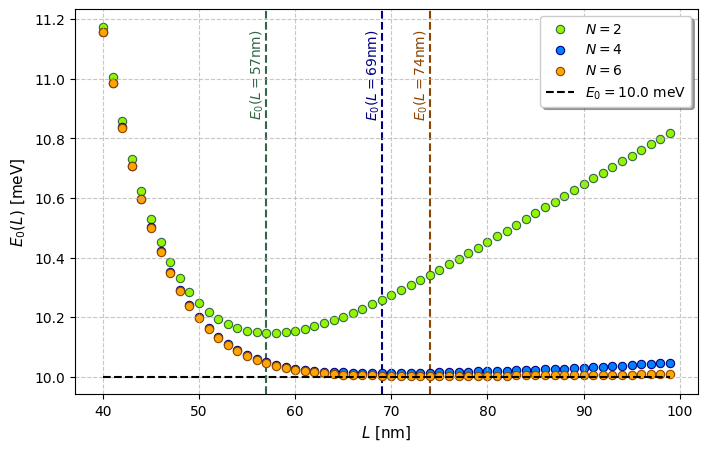

In [15]:
plt.figure(figsize=(8.05 ,5))
colors = {2: {'facecolor': '#93F600', 'edgecolor': '#326647'},
          4: {'facecolor': '#0080FF', 'edgecolor': '#000080'},
          6: {'facecolor': '#FFA500', 'edgecolor': '#8B4500'}}


for N in N_vals:
    mask = results_df["N"] == N
    c = colors[N]
    sub = results_df[mask].sort_values("L_nm")
    min_idx = sub['E0_meV'].idxmin()
    min_L = sub.loc[min_idx, 'L_nm']
    print(f"N={N}, Minimalna energia E_0 = {sub.loc[min_idx, 'E0_meV']} meV dla L = {min_L} nm")
    plt.axvline(min_L, linestyle='--', color=c['edgecolor'], zorder=0)
    plt.text(x=min_L, y=0.95, s=fr'$E_{0}(L={min_L} $nm$)$', transform=plt.gca().get_xaxis_transform(), rotation=90,
        color=c['edgecolor'],ha='right',va='top', fontsize=10 )
    plt.scatter(sub["L_nm"], sub["E0_meV"], label=fr"$N={N}$", 
                facecolor=c['facecolor'], edgecolor=c['edgecolor'], lw=0.8)
E_exact = 10.0 # meV 
plt.hlines(E_exact, min(L_range_nm), max(L_range_nm) , linestyle="--", label=fr"$E_0 =  {E_exact}$ meV", color = 'black')


plt.xlabel(fr"$L$ [nm]", fontsize=11)
plt.ylabel(fr"$E_0(L)$ [meV]", fontsize=11)
plt.legend(shadow = True, loc='upper right')
plt.grid(True, alpha=0.7, ls='--')
plt.savefig(OUTPUT_DIR / "E0_vs_L_dla_roznych_N.pdf", format = 'pdf', bbox_inches='tight')
plt.show()

Najbardziej optymalne: N=4, L=69.0 nm
Wartości E_meV dla pierwszych 6 stanów własnych: [10.01260224 20.05997549 20.05997549 30.10734874 30.27862484 30.27862484]


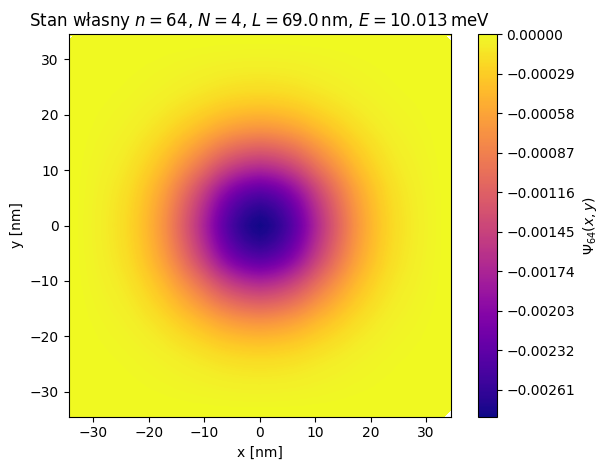

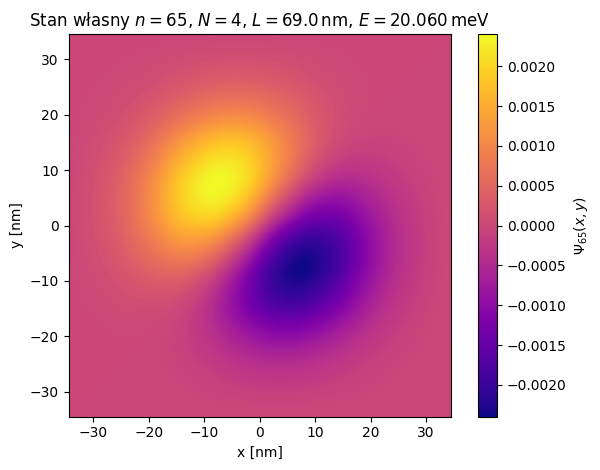

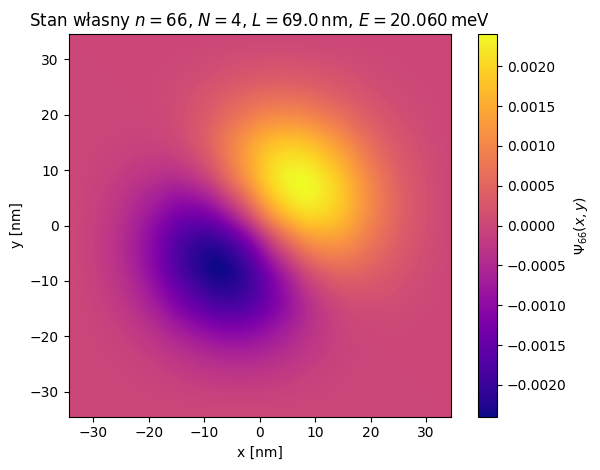

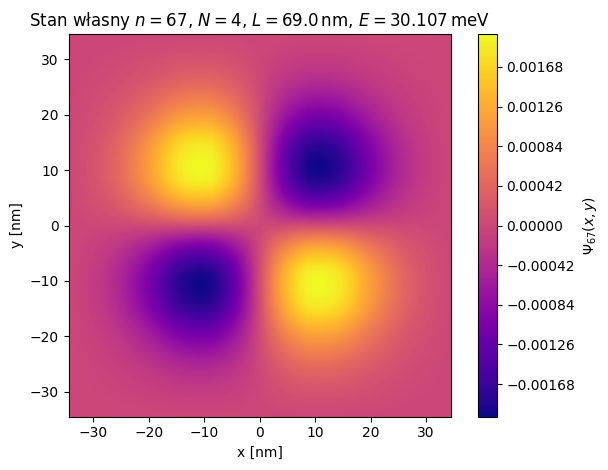

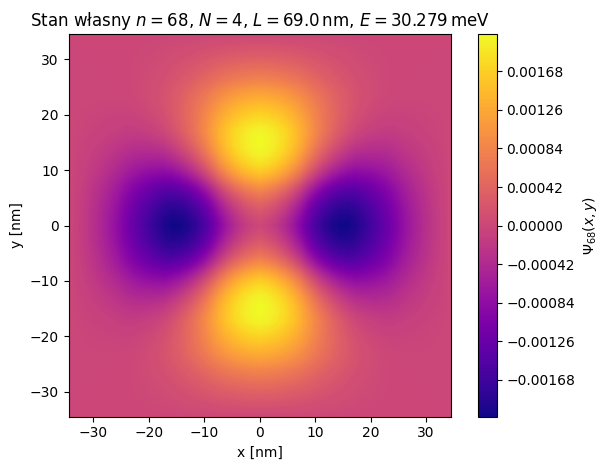

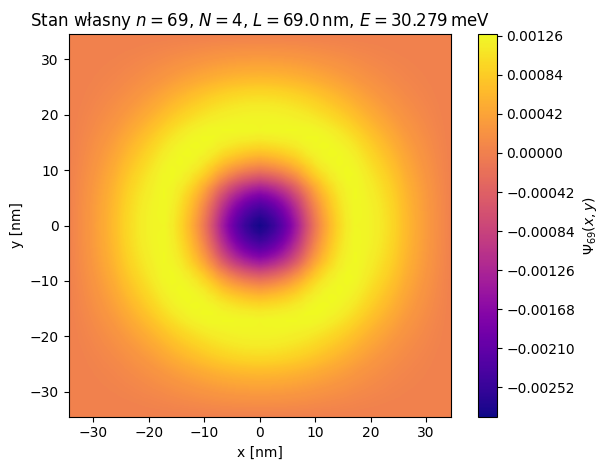

In [16]:
row_opt = results_df[results_df["N"] == 4].sort_values("E0_meV").iloc[0]
N_opt = 4
L_opt_nm = row_opt["L_nm"]
L_opt = L_opt_nm * si.nanometer

print(f"Najbardziej optymalne: N={N_opt}, L={L_opt_nm} nm")

wezly_ref = wezly_ref_dict[N_opt]
nlg_tab = nlg_dict[N_opt]
E0_opt_meV, E_meV, E_au, C = solve_for_L_N(L_opt, N_opt, wezly_ref, nlg_tab, T_loc)
wezly_scaled = scale_nodes_to_L(wezly_ref, L_opt)

pos_mask = E_au > 0
pos_indices = np.where(pos_mask)[0]
first6 = pos_indices[:6]
print('Wartości E_meV dla pierwszych 6 stanów własnych:', E_meV[first6])
for n_idx in first6:
    psi_n = C[:, n_idx].real
    
    xs, ys, vals = eval_psi_on_elements(psi_n, nlg_tab=nlg_tab, wezly_data=wezly_scaled, n_points_per_dir=7)
    
    plt.figure()
    cnt = plt.tricontourf(xs, ys, vals, levels=300, cmap="plasma")
    cnt.set_edgecolor("face") 
    plt.colorbar(cnt, label=rf"$\Psi_{{{n_idx}}}(x,y)$")
    
    plt.title(
        rf"Stan własny $n={n_idx}$, $N={N_opt}$, "
        rf"$L={L_opt_nm:.1f}\,\mathrm{{nm}}$, "
        rf"$E={E_meV[n_idx]:.3f}\,\mathrm{{meV}}$"
    )
    plt.xlabel("x [nm]")
    plt.ylabel("y [nm]")
    plt.gca().set_aspect("equal")
    plt.tight_layout()
    
    plt.savefig(OUTPUT_DIR / f"wavefunction_N{N_opt}_L{int(L_opt_nm)}_n{n_idx}.pdf", format="pdf", bbox_inches="tight")


### Ewolucja w czasie

In [17]:
def compute_X_global(L, N, wezly_N_L_data, nlg_N_L_data):
    n_global = (4 * N + 1)**2
    X_global = np.zeros((n_global, n_global), dtype=complex)

    jac = compute_jacobian(L, N)
    n_elem = int(nlg_N_L_data["k"].max())

    for k in range(1, n_elem + 1):
        rows_k = nlg_N_L_data[nlg_N_L_data["k"] == k]

        # lokalny -> globalny
        local_to_global = {}
        for _, row in rows_k.iterrows():
            local_i = int(row["i"])
            global_i = int(row["glp"])
            local_to_global[local_i] = global_i

        # narożne węzły elementu
        corners_idx = [local_to_global[i] for i in range(1, 5)]

        x_nodes = []
        y_nodes = []
        for glp in corners_idx:
            node_row = wezly_N_L_data[wezly_N_L_data["lp"] == glp].iloc[0]
            x_nodes.append(node_row["x"] * nm_to_bohr)
            y_nodes.append(node_row["y"] * nm_to_bohr)
        x_nodes = np.array(x_nodes)
        y_nodes = np.array(y_nodes) 
        
        # lokalna macierz X dla elementu k
        X_loc_k = np.zeros((n_loc, n_loc), dtype=complex)
        for l in range(4):
            for n in range(4):
                h = h_vec(pi[l], pi[n])
                g = g_vec(pi[l], pi[n])
                x = np.dot(x_nodes, g)  

                X_loc_k += jac * x * wg[l] * wg[n] * np.outer(h, h)

        for i1_local in range(1, 10):
            I = local_to_global[i1_local] - 1
            for i2_local in range(1, 10):
                J = local_to_global[i2_local] - 1
                X_global[I, J] += X_loc_k[i1_local - 1, i2_local - 1]

    return X_global

Ewolucja czasowa dla N=4, L=69.0 nm
E0  = 10.0126 meV
E1  = 20.0600 meV
ΔE = 3.692342e-04 [a.u.], okres T ≈ 17016.80 [a.u.]
Liczba kroków na ~1 okres: n_steps = 170


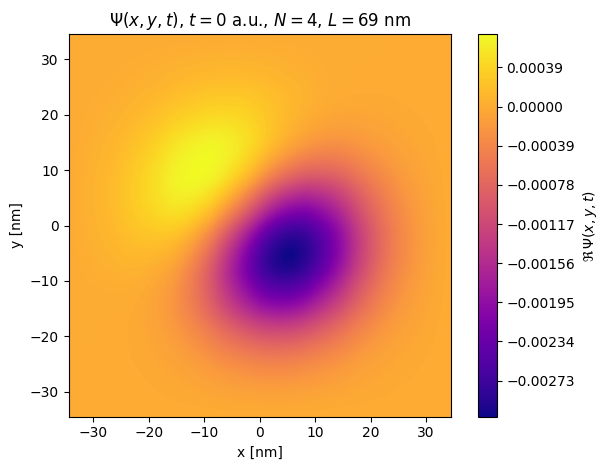

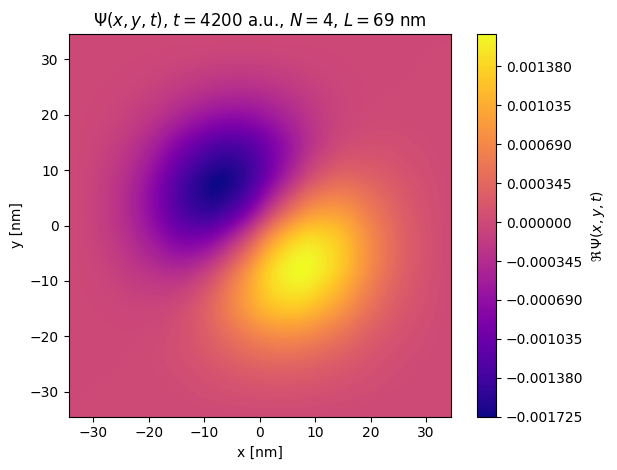

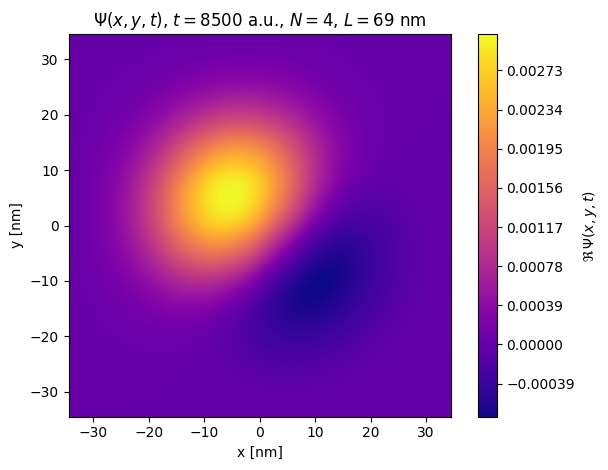

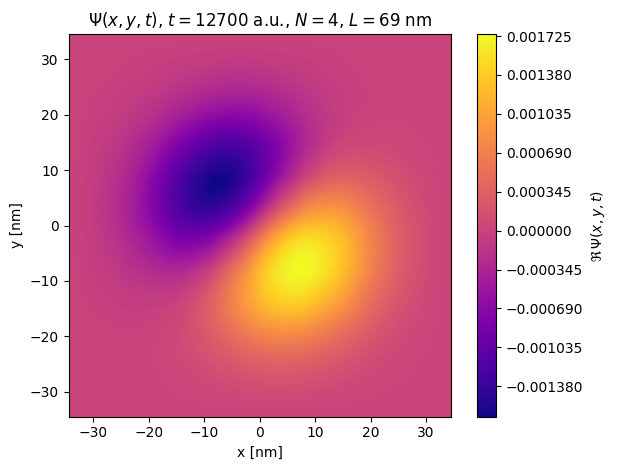

In [18]:
S_loc_evo, _ = compute_S_loc(L_opt, N_opt, n_loc=n_loc)
S_global_evo, H_global_evo, _ = compute_global_matrices(S_loc_evo, T_loc, N=N_opt, L=L_opt, 
                                                        wezly_N_L_data=wezly_scaled, nlg_N_L_data=nlg_tab)

S_bc, H_bc, _ = boundary_conditions(S_global_evo, H_global_evo, wezly_data=wezly_scaled, L=L_opt)
print(f'Ewolucja czasowa dla N={N_opt}, L={L_opt_nm} nm')
pos_mask = E_au > 0
pos_idx = np.where(pos_mask)[0]
g_idx = pos_idx[0]  # stan podstawowy
e_idx = pos_idx[1]  # pierwszy stan wzbudzony

print(f"E0  = {E_meV[g_idx]:.4f} meV")
print(f"E1  = {E_meV[e_idx]:.4f} meV")

DeltaE_au = E_au[e_idx] - E_au[g_idx]
T_theory = 2.0 * np.pi / DeltaE_au 
print(f"ΔE = {DeltaE_au:.6e} [a.u.], okres T ≈ {T_theory:.2f} [a.u.]")

dt = 100.0  # [a.u. czasu]
n_steps = int(np.round(T_theory / dt))
print(f"Liczba kroków na ~1 okres: n_steps = {n_steps}")

X_global_nm = compute_X_global(L_opt, N_opt, wezly_scaled, nlg_tab) / nm_to_bohr

# (S + i dt/2 H) d_{n+1} = (S - i dt/2 H) d_n
alpha = 0.5j * dt
A = S_bc + alpha * H_bc
B = S_bc - alpha * H_bc

# warunek początkowy d(t=0) = c1 + c2
c1 = C[:, g_idx]
c2 = C[:, e_idx]
d_t = c1 + c2
norm0 = np.sqrt(np.real(np.vdot(d_t, S_bc @ d_t)))
d_t /= norm0

times = []
x_vals = []
snap_steps = [0, int(0.25 * n_steps), int(0.50 * n_steps), int(0.75 * n_steps)]

for step in range(n_steps + 1):
    t = step * dt
    times.append(t)

    #  x(t) = d\dagger X d(t) 
    x_t_nm = np.real(np.vdot(d_t, X_global_nm @ d_t))
    x_vals.append(x_t_nm)

    if step in snap_steps:
        xs, ys, vals = eval_psi_on_elements(d_t, nlg_tab=nlg_tab, wezly_data=wezly_scaled, n_points_per_dir=7)
        
        plt.figure()
        cnt = plt.tricontourf(xs, ys, np.real(vals), levels=300, cmap="plasma")
        #psi2 = np.abs(vals)**2  # |\psi|^2
        # cnt = plt.tricontourf(xs, ys, psi2, levels=300, cmap="plasma")
        # plt.colorbar(cnt, label=r"$|\Psi(x,y,t)|^2$")
        # plt.title(rf"$|\Psi(x,y,t)|^2$, $t={t:.1f}$ a.u., "rf"$N={N_opt}$, $L={L_opt_nm:.1f}$ nm")
        cnt.set_edgecolor("face")
        plt.colorbar(cnt, label=r"$\Re\,\Psi(x,y,t)$")
        plt.title(rf"$\Psi(x,y,t)$, $t={t:.0f}$ a.u., $N={N_opt}$, $L={L_opt_nm:.0f}$ nm")
        plt.xlabel("x [nm]")
        plt.ylabel("y [nm]")
        plt.gca().set_aspect("equal")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"psi_snapshot_N{N_opt}_L{int(L_opt_nm)}_step{step}.pdf", format="pdf", bbox_inches="tight")

    if step < n_steps:
        rhs = B @ d_t
        d_t = solve(A, rhs)

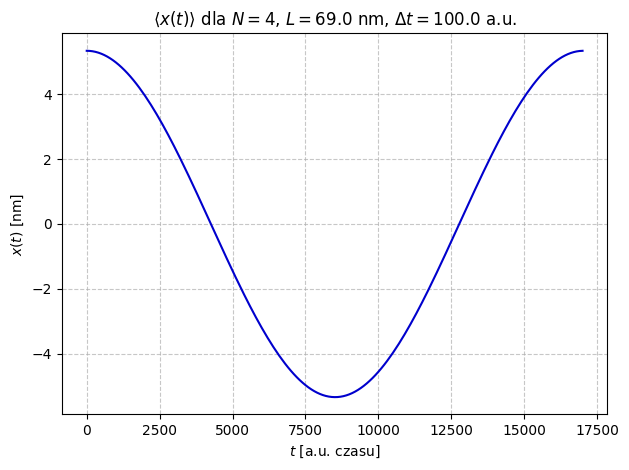

In [19]:
# x(t) w czasie ~jednego okresu
plt.figure()
plt.plot(times, x_vals, lw=1.5, color='mediumblue')
plt.xlabel(r"$t$ [a.u. czasu]")
plt.ylabel(r"$x(t)$ [nm]")
plt.title(
    rf"$\langle x(t)\rangle$ dla $N={N_opt}$, $L={L_opt_nm:.1f}$ nm, "
    rf"$\Delta t={dt}$ a.u.")

plt.grid(True, alpha=0.7, ls='--')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"x_t_N{N_opt}_L{int(L_opt_nm)}.pdf",  format="pdf",  bbox_inches="tight")
plt.show()